In [14]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, spearmanr
from IPython.display import display

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

CSV_PATH = Path("dataset/indonesia_kesehatan_mental_gen_z_akademik_enriched_2026.csv")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {CSV_PATH.resolve()}. Sesuaikan CSV_PATH.")

# Dataset menggunakan pemisah titik koma (;).
df_asli = pd.read_csv(CSV_PATH, sep=";", engine="python")
print("Ukuran dataset:", df_asli.shape)
display(df_asli.head())

Ukuran dataset: (10000, 29)


,responden_id,jenjang_dan_rumpun_studi,status_perguruan_tinggi,provinsi_domisili_kampus,semester_studi,golongan_ukt,indeks_prestasi_kumulatif_ipk,beban_sks_semester_ini,durasi_layar_harian_jam,durasi_tidur_harian_jam,kondisi_tempat_tinggal,pengeluaran_bulanan_total_idr,aktivitas_pekerjaan_sampingan,skor_tekanan_finansial,skor_kecemasan_akademik,skor_tekanan_masa_depan_karir,skor_kesepian_dan_isolasi_sosial,frekuensi_keluhan_somatik_mingguan,akses_layanan_konseling,teks_refleksi_kondisi_mental,panjang_karakter_refleksi,jumlah_kata_refleksi,timestamp_survei,indeks_beban_stres_kumulatif,skor_resiliensi_psikologis,kategori_keparahan_depresi_kecemasan,rasio_defisit_tidur_terhadap_layar,penalaran_psikologis_cot,posterior_confidence
0,GENZ_MHS_2026_00001,Ilmu Sosial & Politik,PTN Badan Hukum (PTN-BH),Kalimantan Tengah,5,UKT Golongan 3-4 (Rp 2jt - 4jt),2.83,18,9.2,6.4,Asrama Mahasiswa,7300000,Freelance / Desain / Coding,3,3,1,1,0,Belum Pernah Karena Malu / Takut Stigma,Ritme perkuliahan semester ini dapat saya jala...,359,48,30/06/2025 13:18,0.37,0.86,Minimal,0.1739,Responden 'GENZ_MHS_2026_00001' adalah mahasis...,0.975
1,GENZ_MHS_2026_00002,Kedokteran & Kesehatan,PTN Badan Hukum (PTN-BH),DKI Jakarta,8,UKT Golongan 7-8 (> Rp 9jt),3.63,18,7.5,6.4,Asrama Mahasiswa,4450000,Tidak Bekerja / Fokus Kuliah,3,5,3,2,3,Belum Pernah Karena Kendala Biaya,Hubungan komunikasi dengan keluarga di kampung...,307,40,31/07/2026 03:11,0.64,0.79,Sedang,0.2133,Responden 'GENZ_MHS_2026_00002' adalah mahasis...,0.988
2,GENZ_MHS_2026_00003,Kedokteran & Kesehatan,PTN Badan Hukum (PTN-BH),Sulawesi Selatan,4,UKT Golongan 1-2 (Rp 500rb - 1jt),3.03,20,6.5,3.6,Tinggal Bersama Orang Tua,2100000,Ojek Online / Kurir Logistik,3,1,1,3,1,Belum Pernah Karena Kendala Biaya,Dukungan finansial dari keluarga mencukupi keb...,251,31,01/11/2025 14:03,0.47,0.88,Ringan,0.6769,Responden 'GENZ_MHS_2026_00003' adalah mahasis...,0.955
3,GENZ_MHS_2026_00004,Ilmu Komputer & IT,PTN BLU / Satker,Nusa Tenggara Timur,5,UKT Golongan 3-4 (Rp 2jt - 4jt),3.61,21,6.3,6.9,Kost Sendiri,3850000,Freelance / Desain / Coding,3,1,3,3,0,Pernah Konseling Telemedisin Online,Fasilitas ruang belajar dan perpustakaan digit...,318,42,26/06/2026 02:08,0.41,0.98,Minimal,0.1746,Responden 'GENZ_MHS_2026_00004' adalah mahasis...,0.983
4,GENZ_MHS_2026_00005,Ilmu Komputer & IT,PTS Akreditasi Unggul,Jawa Timur,5,UKT Golongan 3-4 (Rp 2jt - 4jt),2.98,16,3.8,6.2,Tinggal Bersama Orang Tua,1650000,Tidak Bekerja / Fokus Kuliah,2,5,4,2,4,Konseling Komunitas / Teman Sebaya,Kekhawatiran tentang persaingan mencari kerja ...,365,46,20/07/2025 21:28,0.58,0.97,Sedang,0.4737,Responden 'GENZ_MHS_2026_00005' adalah mahasis...,0.990


In [15]:
GROUP_COL = "jenjang_dan_rumpun_studi"
ID_COL = "responden_id"

CRITERIA = {
    "C1": {"name": "Kecemasan akademik", "column": "skor_kecemasan_akademik", "type": "benefit"},
    "C2": {"name": "Tekanan finansial", "column": "skor_tekanan_finansial", "type": "benefit"},
    "C3": {"name": "Tekanan masa depan karier", "column": "skor_tekanan_masa_depan_karir", "type": "benefit"},
    "C4": {"name": "Kesepian & isolasi sosial", "column": "skor_kesepian_dan_isolasi_sosial", "type": "benefit"},
    "C5": {"name": "Keluhan somatik per minggu", "column": "frekuensi_keluhan_somatik_mingguan", "type": "benefit"},
    "C6": {"name": "Durasi tidur (jam)", "column": "durasi_tidur_harian_jam", "type": "cost"},
    "C7": {"name": "Resiliensi psikologis", "column": "skor_resiliensi_psikologis", "type": "cost"},
}
CODES = list(CRITERIA)
CRITERIA_COLS = [CRITERIA[c]["column"] for c in CODES]
CRITERIA_NAMES = [CRITERIA[c]["name"] for c in CODES]
CRITERIA_TYPES = [CRITERIA[c]["type"] for c in CODES]

ALTERNATIVES = [
    "Ekonomi & Bisnis", "Hukum", "Ilmu Komputer & IT",
    "Ilmu Sosial & Politik", "Kedokteran & Kesehatan",
    "MIPA & Sains Murni", "Pendidikan & Keguruan",
    "Sastra & Seni Desain", "Teknik & Rekayasa"
]

STRESS_COL = "indeks_beban_stres_kumulatif"
SEVERITY_COL = "kategori_keparahan_depresi_kecemasan"

required = [ID_COL, GROUP_COL] + CRITERIA_COLS + [STRESS_COL, SEVERITY_COL]
missing = [c for c in required if c not in df_asli.columns]
if missing:
    raise ValueError(f"Kolom dataset tidak ditemukan: {missing}")
print("Semua kolom penelitian tersedia.")

Semua kolom penelitian tersedia.


In [16]:
df = df_asli[required].copy()
df[GROUP_COL] = df[GROUP_COL].astype("string").str.strip()

for col in CRITERIA_COLS + [STRESS_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

duplicate_ids = int(df[ID_COL].duplicated().sum())
df = df.drop_duplicates(subset=ID_COL, keep="first")
before_dropna = len(df)
df = df.dropna(subset=[GROUP_COL] + CRITERIA_COLS + [STRESS_COL, SEVERITY_COL])
removed_missing = before_dropna - len(df)

print("Duplikasi ID dihapus:", duplicate_ids)
print("Baris dengan nilai kosong dihapus:", removed_missing)
print("Responden setelah preprocessing:", len(df))
print("Duplikasi baris penuh tersisa:", df.duplicated().sum())

# Pemeriksaan rentang skala menurut artikel.
ranges = {
    "skor_kecemasan_akademik": (1, 5),
    "skor_tekanan_finansial": (1, 5),
    "skor_tekanan_masa_depan_karir": (1, 5),
    "skor_kesepian_dan_isolasi_sosial": (1, 5),
    "frekuensi_keluhan_somatik_mingguan": (0, 7),
    "durasi_tidur_harian_jam": (2.5, 9.5),
    "skor_resiliensi_psikologis": (0.50, 0.98),
}
checks = []
for col, (lo, hi) in ranges.items():
    checks.append({"Kolom": col, "Min aktual": df[col].min(), "Max aktual": df[col].max(),
                   "Rentang artikel": f"{lo}–{hi}", "Sesuai": df[col].between(lo, hi).all()})
range_df = pd.DataFrame(checks)
display(range_df)
if not range_df["Sesuai"].all():
    raise ValueError("Ada nilai di luar rentang skala artikel; periksa dataset.")

Duplikasi ID dihapus: 0
Baris dengan nilai kosong dihapus: 0
Responden setelah preprocessing: 10000
Duplikasi baris penuh tersisa: 0


,Kolom,Min aktual,Max aktual,Rentang artikel,Sesuai
0,skor_kecemasan_akademik,1.0,5.00,1–5,True
1,skor_tekanan_finansial,1.0,5.00,1–5,True
2,skor_tekanan_masa_depan_karir,1.0,5.00,1–5,True
3,skor_kesepian_dan_isolasi_sosial,1.0,5.00,1–5,True
4,frekuensi_keluhan_somatik_mingguan,0.0,7.00,0–7,True
5,durasi_tidur_harian_jam,2.5,9.50,2.5–9.5,True
6,skor_resiliensi_psikologis,0.5,0.98,0.5–0.98,True


In [17]:
found = sorted(df[GROUP_COL].unique().tolist())
print("Rumpun ditemukan:", found)
if set(found) != set(ALTERNATIVES):
    raise ValueError(f"Alternatif dataset tidak sama dengan artikel: {set(found).symmetric_difference(ALTERNATIVES)}")

respondent_counts = df.groupby(GROUP_COL).size().reindex(ALTERNATIVES)
display(respondent_counts.rename("Jumlah responden").to_frame())

Rumpun ditemukan: ['Ekonomi & Bisnis', 'Hukum', 'Ilmu Komputer & IT', 'Ilmu Sosial & Politik', 'Kedokteran & Kesehatan', 'MIPA & Sains Murni', 'Pendidikan & Keguruan', 'Sastra & Seni Desain', 'Teknik & Rekayasa']


,Jumlah responden
jenjang_dan_rumpun_studi,
Ekonomi & Bisnis,1501
Hukum,784
Ilmu Komputer & IT,1660
Ilmu Sosial & Politik,1088
Kedokteran & Kesehatan,1162
MIPA & Sains Murni,693
Pendidikan & Keguruan,823
Sastra & Seni Desain,484
Teknik & Rekayasa,1805


In [18]:
X = df.groupby(GROUP_COL)[CRITERIA_COLS].mean().reindex(ALTERNATIVES)
X.columns = CODES
X.index.name = "Alternatif"

X_display = X.copy()
X_display.insert(0, "Jumlah responden", respondent_counts)
display(X_display.round(6))
print("Ukuran matriks keputusan:", X.shape)
assert X.shape == (9, 7)
assert not X.isna().any().any()

,Jumlah responden,C1,C2,C3,C4,C5,C6,C7
Alternatif,,,,,,,,
Ekonomi & Bisnis,1501,3.285809,3.225849,3.381079,2.652232,2.471686,6.009594,0.865630
Hukum,784,3.315051,3.330357,3.376276,2.718112,2.508929,5.976148,0.852615
Ilmu Komputer & IT,1660,3.283735,3.347590,3.400000,2.674096,2.601205,6.090422,0.862880
Ilmu Sosial & Politik,1088,3.298713,3.328125,3.413603,2.637868,2.545037,6.024908,0.866314
Kedokteran & Kesehatan,1162,3.267642,3.220310,3.452668,2.668675,2.485370,5.929776,0.860181
MIPA & Sains Murni,693,3.278499,3.313131,3.434343,2.796537,2.580087,5.976046,0.859654
Pendidikan & Keguruan,823,3.273390,3.268530,3.420413,2.718104,2.580802,5.989915,0.861968
Sastra & Seni Desain,484,3.293388,3.280992,3.545455,2.638430,2.611570,5.949587,0.858430
Teknik & Rekayasa,1805,3.299169,3.314681,3.454848,2.710249,2.570083,5.977008,0.861767


Ukuran matriks keputusan: (9, 7)


In [ ]:
A = np.array([
    [1,   1,   2,   1,   1,   2,   1],
    [1,   1,   1,   1,   1,   1,   1],
    [1/2, 1,   1,   1,   1,   1,   1],
    [1,   1,   1,   1,   1,   1,   1],
    [1,   1,   1,   1,   1,   1,   1],
    [1/2, 1,   1,   1,   1,   1,   1],
    [1,   1,   1,   1,   1,   1,   1],
], dtype=float)

RI = 1.32
A_df = pd.DataFrame(A, index=CODES, columns=CODES)
display(A_df)
assert np.allclose(A * A.T, 1.0), "Matriks tidak reciprocal."
assert np.allclose(np.diag(A), 1.0)

column_sums = A.sum(axis=0)
A_norm = A / column_sums
weights = A_norm.mean(axis=1)

A_norm_df = pd.DataFrame(A_norm, index=CODES, columns=CODES)
weights_df = pd.DataFrame({
    "Kriteria": CRITERIA_NAMES,
    "Bobot AHP": weights,
    "Tipe": CRITERIA_TYPES
}, index=CODES)
display(A_norm_df.round(6))
display(weights_df.round(6))
print("Total bobot:", weights.sum())

,C1,C2,C3,C4,C5,C6,C7
C1,1.0,1.0,2.0,1.0,1.0,2.0,1.0
C2,1.0,1.0,1.0,1.0,1.0,1.0,1.0
C3,0.5,1.0,1.0,1.0,1.0,1.0,1.0
C4,1.0,1.0,1.0,1.0,1.0,1.0,1.0
C5,1.0,1.0,1.0,1.0,1.0,1.0,1.0
C6,0.5,1.0,1.0,1.0,1.0,1.0,1.0
C7,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,C1,C2,C3,C4,C5,C6,C7
C1,0.166667,0.142857,0.250,0.142857,0.142857,0.250,0.142857
C2,0.166667,0.142857,0.125,0.142857,0.142857,0.125,0.142857
C3,0.083333,0.142857,0.125,0.142857,0.142857,0.125,0.142857
C4,0.166667,0.142857,0.125,0.142857,0.142857,0.125,0.142857
C5,0.166667,0.142857,0.125,0.142857,0.142857,0.125,0.142857
C6,0.083333,0.142857,0.125,0.142857,0.142857,0.125,0.142857
C7,0.166667,0.142857,0.125,0.142857,0.142857,0.125,0.142857


,Kriteria,Bobot AHP,Tipe
C1,Kecemasan akademik,0.176871,benefit
C2,Tekanan finansial,0.141156,benefit
C3,Tekanan masa depan karier,0.129252,benefit
C4,Kesepian & isolasi sosial,0.141156,benefit
C5,Keluhan somatik per minggu,0.141156,benefit
C6,Durasi tidur (jam),0.129252,cost
C7,Resiliensi psikologis,0.141156,cost


Total bobot: 0.9999999999999999


In [20]:
Aw = A @ weights
lambda_values = Aw / weights
lambda_max = lambda_values.mean()
n = len(CODES)
CI = (lambda_max - n) / (n - 1)
CR = CI / RI

consistency_df = pd.DataFrame({
    "Bobot W": weights,
    "A x W": Aw,
    "(A x W) / W": lambda_values
}, index=CODES)
display(consistency_df.round(6))
print(f"Lambda maksimum = {lambda_max:.6f}")
print(f"CI = {CI:.6f}")
print(f"RI = {RI:.2f}")
print(f"CR = {CR:.6f}")
print("Status:", "KONSISTEN (CR ≤ 0,10)" if CR <= 0.10 else "PERLU REVISI")
if CR > 0.10:
    raise ValueError("Matriks AHP tidak memenuhi CR ≤ 0,10.")

,Bobot W,A x W,(A x W) / W
C1,0.176871,1.258503,7.115385
C2,0.141156,1.000000,7.084337
C3,0.129252,0.911565,7.052632
C4,0.141156,1.000000,7.084337
C5,0.141156,1.000000,7.084337
C6,0.129252,0.911565,7.052632
C7,0.141156,1.000000,7.084337


Lambda maksimum = 7.079714
CI = 0.013286
RI = 1.32
CR = 0.010065
Status: KONSISTEN (CR ≤ 0,10)


In [21]:
R = X / np.sqrt((X ** 2).sum(axis=0))
R_df = pd.DataFrame(R, index=X.index, columns=CODES)
display(R_df.round(6))

Y = R.mul(weights, axis=1)
Y_df = pd.DataFrame(Y, index=X.index, columns=CODES)
display(Y_df.round(6))

,C1,C2,C3,C4,C5,C6,C7
Alternatif,,,,,,,
Ekonomi & Bisnis,0.333070,0.326589,0.328454,0.328542,0.322972,0.334332,0.335103
Hukum,0.336034,0.337170,0.327987,0.336703,0.327838,0.332471,0.330065
Ilmu Komputer & IT,0.332860,0.338915,0.330292,0.331251,0.339896,0.338828,0.334039
Ilmu Sosial & Politik,0.334378,0.336944,0.331614,0.326763,0.332557,0.335184,0.335368
Kedokteran & Kesehatan,0.331228,0.326029,0.335409,0.330579,0.324760,0.329891,0.332994
MIPA & Sains Murni,0.332329,0.335426,0.333628,0.346418,0.337137,0.332465,0.332790
Pendidikan & Keguruan,0.331811,0.330910,0.332275,0.336702,0.337230,0.333237,0.333686
Sastra & Seni Desain,0.333838,0.332172,0.344422,0.326833,0.341251,0.330993,0.332316
Teknik & Rekayasa,0.334424,0.335583,0.335620,0.335729,0.335829,0.332519,0.333608


,C1,C2,C3,C4,C5,C6,C7
Alternatif,,,,,,,
Ekonomi & Bisnis,0.058910,0.046100,0.042453,0.046376,0.045590,0.043213,0.047302
Hukum,0.059435,0.047594,0.042393,0.047528,0.046277,0.042972,0.046591
Ilmu Komputer & IT,0.058873,0.047840,0.042691,0.046758,0.047979,0.043794,0.047152
Ilmu Sosial & Politik,0.059142,0.047562,0.042862,0.046125,0.046943,0.043323,0.047339
Kedokteran & Kesehatan,0.058585,0.046021,0.043352,0.046663,0.045842,0.042639,0.047004
MIPA & Sains Murni,0.058779,0.047348,0.043122,0.048899,0.047589,0.042972,0.046975
Pendidikan & Keguruan,0.058688,0.046710,0.042947,0.047528,0.047602,0.043071,0.047102
Sastra & Seni Desain,0.059046,0.046888,0.044517,0.046135,0.048170,0.042781,0.046909
Teknik & Rekayasa,0.059150,0.047370,0.043380,0.047390,0.047404,0.042979,0.047091


In [22]:
A_plus = pd.Series(index=CODES, dtype=float)
A_minus = pd.Series(index=CODES, dtype=float)

for c in CODES:
    if CRITERIA[c]["type"] == "benefit":
        A_plus[c] = Y_df[c].max()
        A_minus[c] = Y_df[c].min()
    else:  # cost
        A_plus[c] = Y_df[c].min()
        A_minus[c] = Y_df[c].max()

ideal_df = pd.DataFrame({"A+": A_plus, "A-": A_minus, "Tipe": CRITERIA_TYPES}, index=CODES)
display(ideal_df.round(6))

D_plus = np.sqrt(((Y_df - A_plus) ** 2).sum(axis=1))
D_minus = np.sqrt(((Y_df - A_minus) ** 2).sum(axis=1))

Vi = D_minus / (D_plus + D_minus)
ranking = pd.DataFrame({"D+": D_plus, "D-": D_minus, "Nilai preferensi (Vi)": Vi}, index=X.index)
ranking["Peringkat"] = ranking["Nilai preferensi (Vi)"].rank(ascending=False, method="min").astype(int)
ranking = ranking.sort_values("Nilai preferensi (Vi)", ascending=False)
display(ranking.style.format({"D+": "{:.6f}", "D-": "{:.6f}", "Nilai preferensi (Vi)": "{:.6f}"}))
assert sorted(ranking["Peringkat"].tolist()) == list(range(1, 10))
print("Hasil akhir TOPSIS mencakup seluruh 9 alternatif (peringkat 1–9).")

,A+,A-,Tipe
C1,0.059435,0.058585,benefit
C2,0.047840,0.046021,benefit
C3,0.044517,0.042393,benefit
C4,0.048899,0.046125,benefit
C5,0.048170,0.045590,benefit
C6,0.042639,0.043794,cost
C7,0.046591,0.047339,cost


,D+,D-,Nilai preferensi (Vi),Peringkat
Alternatif,,,,
MIPA & Sains Murni,0.001793,0.003851,0.682361,1
Teknik & Rekayasa,0.002196,0.002955,0.573665,2
Sastra & Seni Desain,0.002970,0.003653,0.551576,3
Pendidikan & Keguruan,0.002636,0.002719,0.507668,4
Ilmu Komputer & IT,0.003150,0.003102,0.496216,5
Hukum,0.003186,0.002621,0.451416,6
Ilmu Sosial & Politik,0.003624,0.002226,0.380521,7
Kedokteran & Kesehatan,0.003997,0.001649,0.292119,8
Ekonomi & Bisnis,0.004628,0.000720,0.134611,9


Hasil akhir TOPSIS mencakup seluruh 9 alternatif (peringkat 1–9).


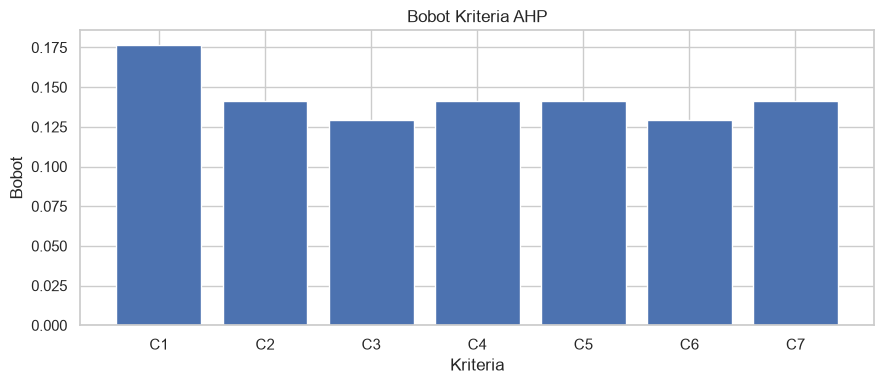

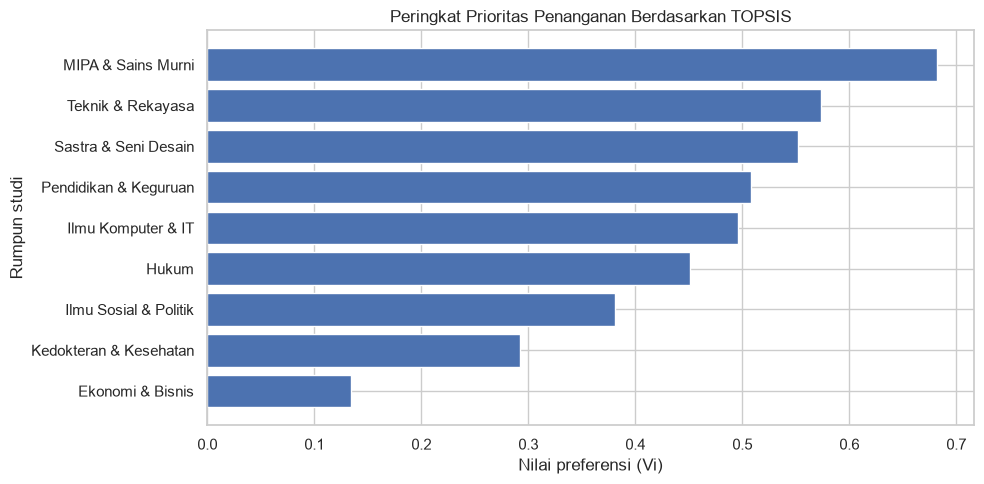

In [23]:
plt.figure(figsize=(9, 4))
plt.bar(weights_df.index, weights_df["Bobot AHP"])
plt.title("Bobot Kriteria AHP")
plt.xlabel("Kriteria")
plt.ylabel("Bobot")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
rank_plot = ranking.sort_values("Nilai preferensi (Vi)")
plt.barh(rank_plot.index, rank_plot["Nilai preferensi (Vi)"])
plt.title("Peringkat Prioritas Penanganan Berdasarkan TOPSIS")
plt.xlabel("Nilai preferensi (Vi)")
plt.ylabel("Rumpun studi")
plt.tight_layout()
plt.show()

In [24]:
def topsis_score(data, w):
    arr = np.asarray(data, dtype=float)
    w = np.asarray(w, dtype=float)
    norm = arr / np.sqrt((arr ** 2).sum(axis=0))
    weighted = norm * w
    benefit_mask = np.array(CRITERIA_TYPES) == "benefit"
    ideal_pos = np.where(benefit_mask, weighted.max(axis=0), weighted.min(axis=0))
    ideal_neg = np.where(benefit_mask, weighted.min(axis=0), weighted.max(axis=0))
    d_pos = np.sqrt(((weighted - ideal_pos) ** 2).sum(axis=1))
    d_neg = np.sqrt(((weighted - ideal_neg) ** 2).sum(axis=1))
    return pd.Series(d_neg / (d_pos + d_neg), index=X.index)

base_rank = ranking["Peringkat"].reindex(X.index)
sensitivity = []

# Skenario bobot sama rata.
w_equal = np.ones(len(weights)) / len(weights)
s_equal = topsis_score(X.values, w_equal)
r_equal = s_equal.rank(ascending=False, method="min").astype(int)
rho, _ = spearmanr(base_rank, r_equal)
sensitivity.append({"Skenario": "Bobot sama rata", "Spearman": rho,
                    "Rata-rata perubahan ranking": np.mean(abs(base_rank-r_equal)),
                    "Peringkat pertama": s_equal.idxmax()})

# Skenario perubahan bobot masing-masing kriteria sebesar -10% dan +10%.
for j, c in enumerate(CODES):
    for factor in [0.9, 1.1]:
        w_new = weights.copy()
        w_new[j] *= factor
        w_new /= w_new.sum()
        score = topsis_score(X.values, w_new)
        rank_new = score.rank(ascending=False, method="min").astype(int)
        rho, _ = spearmanr(base_rank, rank_new)
        sensitivity.append({"Skenario": f"{c} x {factor:.1f}", "Spearman": rho,
                            "Rata-rata perubahan ranking": np.mean(abs(base_rank-rank_new)),
                            "Peringkat pertama": score.idxmax()})

sensitivity_df = pd.DataFrame(sensitivity)
display(sensitivity_df.round(4))

,Skenario,Spearman,Rata-rata perubahan ranking,Peringkat pertama
0,Bobot sama rata,1.0000,0.0000,MIPA & Sains Murni
1,C1 x 0.9,1.0000,0.0000,MIPA & Sains Murni
2,C1 x 1.1,1.0000,0.0000,MIPA & Sains Murni
3,C2 x 0.9,1.0000,0.0000,MIPA & Sains Murni
4,C2 x 1.1,0.9833,0.2222,MIPA & Sains Murni
5,C3 x 0.9,1.0000,0.0000,MIPA & Sains Murni
6,C3 x 1.1,1.0000,0.0000,MIPA & Sains Murni
7,C4 x 0.9,1.0000,0.0000,MIPA & Sains Murni
8,C4 x 1.1,1.0000,0.0000,MIPA & Sains Murni
9,C5 x 0.9,1.0000,0.0000,MIPA & Sains Murni


In [25]:
def saw_score(data, w):
    arr = np.asarray(data, dtype=float)
    normalized = np.zeros_like(arr)
    for j, typ in enumerate(CRITERIA_TYPES):
        col = arr[:, j]
        if typ == "benefit":
            normalized[:, j] = col / col.max()
        else:
            if np.any(col == 0):
                raise ValueError("Ada nilai nol pada kriteria cost; evaluasi formula SAW cost.")
            normalized[:, j] = col.min() / col
    return pd.Series(normalized @ np.asarray(w), index=X.index)

saw_values = saw_score(X.values, weights)
saw_ranks = saw_values.rank(ascending=False, method="min").astype(int)
topsis_ranks = ranking["Peringkat"].reindex(X.index)
rho_saw, p_saw = spearmanr(topsis_ranks, saw_ranks)

saw_comparison = pd.DataFrame({
    "Nilai TOPSIS": ranking["Nilai preferensi (Vi)"].reindex(X.index),
    "Peringkat TOPSIS": topsis_ranks,
    "Nilai SAW": saw_values,
    "Peringkat SAW": saw_ranks
}).sort_values("Peringkat TOPSIS")
display(saw_comparison.round(6))
print(f"Spearman TOPSIS vs SAW = {rho_saw:.4f}; p-value = {p_saw:.6g}")

,Nilai TOPSIS,Peringkat TOPSIS,Nilai SAW,Peringkat SAW
Alternatif,,,,
MIPA & Sains Murni,0.682361,1,0.988688,1
Teknik & Rekayasa,0.573665,2,0.985343,3
Sastra & Seni Desain,0.551576,3,0.986669,2
Pendidikan & Keguruan,0.507668,4,0.981434,5
Ilmu Komputer & IT,0.496216,5,0.981198,6
Hukum,0.451416,6,0.982597,4
Ilmu Sosial & Politik,0.380521,7,0.977623,7
Kedokteran & Kesehatan,0.292119,8,0.974204,8
Ekonomi & Bisnis,0.134611,9,0.968630,9


Spearman TOPSIS vs SAW = 0.9333; p-value = 0.0002359


In [26]:
validation = df.groupby(GROUP_COL).agg(
    Rata_rata_indeks_stres=(STRESS_COL, "mean"),
    Jumlah_responden=(ID_COL, "count")
).reindex(ALTERNATIVES)

severity_text = df[SEVERITY_COL].astype(str).str.strip().str.lower()
df["_berat_kritis"] = severity_text.isin(["berat / kritis", "berat/kritis", "berat", "kritis"])
validation["Proporsi_Berat_Kritis"] = df.groupby(GROUP_COL)["_berat_kritis"].mean().reindex(ALTERNATIVES)
validation["Peringkat_TOPSIS"] = ranking["Peringkat"].reindex(ALTERNATIVES)
validation["Peringkat_indeks_stres"] = validation["Rata_rata_indeks_stres"].rank(ascending=False, method="min")
validation["Peringkat_proporsi_berat"] = validation["Proporsi_Berat_Kritis"].rank(ascending=False, method="min")

rho_stress, p_stress = spearmanr(validation["Peringkat_TOPSIS"], validation["Peringkat_indeks_stres"])
rho_severity, p_severity = spearmanr(validation["Peringkat_TOPSIS"], validation["Peringkat_proporsi_berat"])
display(validation.round(6))
print(f"Spearman TOPSIS vs indeks stres: rho={rho_stress:.4f}, p={p_stress:.6g}")
print(f"Spearman TOPSIS vs proporsi Berat/Kritis: rho={rho_severity:.4f}, p={p_severity:.6g}")

,Rata_rata_indeks_stres,Jumlah_responden,Proporsi_Berat_Kritis,Peringkat_TOPSIS,Peringkat_indeks_stres,Peringkat_proporsi_berat
jenjang_dan_rumpun_studi,,,,,,
Ekonomi & Bisnis,0.551286,1501,0.133245,9,9.0,9.0
Hukum,0.561454,784,0.150510,6,2.0,3.0
Ilmu Komputer & IT,0.556349,1660,0.147590,5,7.0,5.0
Ilmu Sosial & Politik,0.556489,1088,0.135110,7,6.0,8.0
Kedokteran & Kesehatan,0.552263,1162,0.141136,8,8.0,7.0
MIPA & Sains Murni,0.564675,693,0.152958,1,1.0,2.0
Pendidikan & Keguruan,0.556744,823,0.155529,4,5.0,1.0
Sastra & Seni Desain,0.558616,484,0.148760,3,4.0,4.0
Teknik & Rekayasa,0.560011,1805,0.142382,2,3.0,6.0


Spearman TOPSIS vs indeks stres: rho=0.8000, p=0.00962792
Spearman TOPSIS vs proporsi Berat/Kritis: rho=0.6833, p=0.0424423


In [27]:
kw_rows = []
for c, col in zip(CODES, CRITERIA_COLS):
    samples = [g[col].dropna().to_numpy() for _, g in df.groupby(GROUP_COL)]
    H, p = kruskal(*samples)
    kw_rows.append({
        "Kode": c,
        "Kriteria": CRITERIA[c]["name"],
        "H-statistic": H,
        "p-value": p,
        "Kesimpulan alpha 0.05": "Berbeda signifikan" if p < 0.05 else "Tidak signifikan"
    })

kruskal_df = pd.DataFrame(kw_rows)
display(kruskal_df.round(6))

,Kode,Kriteria,H-statistic,p-value,Kesimpulan alpha 0.05
0,C1,Kecemasan akademik,0.770283,0.999325,Tidak signifikan
1,C2,Tekanan finansial,16.004187,0.042320,Berbeda signifikan
2,C3,Tekanan masa depan karier,9.630311,0.291937,Tidak signifikan
3,C4,Kesepian & isolasi sosial,11.883994,0.156455,Tidak signifikan
4,C5,Keluhan somatik per minggu,9.390169,0.310458,Tidak signifikan
5,C6,Durasi tidur (jam),15.166070,0.055996,Tidak signifikan
6,C7,Resiliensi psikologis,11.372533,0.181471,Tidak signifikan


In [31]:
print("RINGKASAN EKSPERIMEN")
print("Jumlah responden:", len(df))
print("Jumlah alternatif:", len(ALTERNATIVES))
print("Jumlah kriteria:", len(CODES))
print(f"CR AHP: {CR:.6f}")
print("\nRanking TOPSIS:")
for _, row in ranking.iterrows():
    print(f"{int(row['Peringkat'])}. {row.name}: Vi={row['Nilai preferensi (Vi)']:.6f}")

hasil = {
    "Data_Preprocessing": df,
    "Matriks_Keputusan": X,
    "Matriks_AHP": A_df,
    "Normalisasi_AHP": A_norm_df,
    "Bobot_AHP": weights_df,
    "Uji_Konsistensi": consistency_df,
    "Normalisasi_TOPSIS": R_df,
    "Terbobot_TOPSIS": Y_df,
    "Solusi_Ideal": ideal_df,
    "Hasil_TOPSIS": ranking,
    "Sensitivitas": sensitivity_df,
    "TOPSIS_vs_SAW": saw_comparison,
    "Validasi": validation,
    "Kruskal_Wallis": kruskal_df
}

OUTPUT_DIR = Path("Hasil_Eksperimen_CSV")
OUTPUT_DIR.mkdir(exist_ok=True)

for nama, tabel in hasil.items():
    tabel.to_csv(
        OUTPUT_DIR / f"{nama}.csv",
        sep=";",
        encoding="utf-8-sig",
        index=True
    )

print("Semua hasil eksperimen berhasil diekspor ke CSV.")

RINGKASAN EKSPERIMEN
Jumlah responden: 10000
Jumlah alternatif: 9
Jumlah kriteria: 7
CR AHP: 0.010065

Ranking TOPSIS:
1. MIPA & Sains Murni: Vi=0.682361
2. Teknik & Rekayasa: Vi=0.573665
3. Sastra & Seni Desain: Vi=0.551576
4. Pendidikan & Keguruan: Vi=0.507668
5. Ilmu Komputer & IT: Vi=0.496216
6. Hukum: Vi=0.451416
7. Ilmu Sosial & Politik: Vi=0.380521
8. Kedokteran & Kesehatan: Vi=0.292119
9. Ekonomi & Bisnis: Vi=0.134611
Semua hasil eksperimen berhasil diekspor ke CSV.
